# Trabalho Final — Visão Computacional e Percepção
## Pipeline fechado de reconhecimento de padrões em microRNA

**Escopo deste notebook:** apenas bases com rótulo clínico explícito de respondedor/não-respondedor (R/NR). Dados sem o desfecho clínico alvo ficam fora deste trabalho e serão tratados no TCC.

| Papel | Dataset | Doença | Amostras | Rótulo | Plataforma |
|---|---|---|---:|---|---|
| Treino | GSE106894 | Artrite reumatoide | 12 (6 R / 6 NR) | R/NR explícito | Affymetrix miRNA 4.0 |
| Teste Zero-Shot | GSE131703 | Miastenia Gravis | 30 (15 R / 15 NR) | R/NR explícito | miRNA-seq |

**Pergunta:** uma assinatura de miRNAs aprendida na artrite reumatoide transfere para a miastenia gravis sem re-treino?

**Fluxo fechado:** EDA → alinhamento por miRNA → LASSO (seleção dentro do fold) → SVM → CV repetida/LOOCV → teste Zero-Shot congelado.

**Decisão metodológica:** o GSE131703 só é usado na última etapa. Ele não participa de seleção de features, padronização, escolha de hiperparâmetros ou definição de limiar.

## Etapa 1 — Dados e escopo

- **GSE106894:** 12 amostras de PBMC de pacientes com artrite reumatoide em estágio inicial, tratados com TwHF; 6 respondedores e 6 não-respondedores. A plataforma é microarray (GPL21572), com anotação sonda → miRNA.
- **GSE131703:** 30 amostras de sangue total de pacientes com miastenia gravis; 15 respondedores (`MG_R*`) e 15 não-respondedores (`MG_NR*`). Os dados são contagens de miRNA-seq, normalizadas por log-CPM.
- **Fora do escopo:** GSE140106, GSE215450 e GSE230064 não têm rótulo R/NR explícito nos metadados do GEO. Elas não entram neste notebook.

**Limitação central:** o treino tem n = 12 e p = 2.578 miRNAs. Qualquer assinatura aprendida nesse cenário é exploratória e instável; o notebook quantifica essa instabilidade em vez de escondê-la.

### Dependências

```bash
pip install pandas numpy scikit-learn matplotlib seaborn GEOparse openpyxl
```

In [1]:
# Bibliotecas padrão: logging, avisos, contagem e manipulação de caminhos.
import logging
import warnings
from collections import Counter
from pathlib import Path

# Bibliotecas de dados, gráficos e acesso aos datasets do GEO.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import GEOparse
from IPython.display import display

# Componentes de modelagem, validação, métricas e seleção de features.
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.linear_model import Lasso
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    LeaveOneOut,
    RepeatedStratifiedKFold,
    cross_val_predict,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Configuração global: silencia avisos, define estilo dos gráficos e caminhos.
warnings.filterwarnings("ignore")
logging.getLogger("GEOparse").setLevel(logging.WARNING)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

RANDOM_STATE = 42
DATA_DIR = Path("datasets")
RESULTS_DIR = Path("resultados")
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

print("Configuração concluída.")

Configuração concluída.


## Etapa 2 — Carregamento e anotação

As funções abaixo convertem sondas Affymetrix em nomes de miRNA, agregam sondas duplicadas pela média e normalizam as contagens do GSE131703 por log-CPM. O alinhamento entre treino e teste é feito pela interseção dos nomes de miRNA, sem usar rótulos.

In [2]:
def _download(url: str, path: Path) -> Path:
    '''Baixa um arquivo apenas se ele ainda não existir localmente.'''
    if not path.exists():
        import urllib.request
        urllib.request.urlretrieve(url, path)
    return path


def _parse_response(value) -> float:
    '''Converte o rótulo textual do GSE106894 para 1 (R) / 0 (NR).'''
    text = str(value).strip().lower()
    if text in {"responder", "r", "1"}:
        return 1.0
    if text in {"non-responder", "non responder", "nr", "0"}:
        return 0.0
    return np.nan


def _parse_mg_label(sample: str) -> float:
    '''Extrai o rótulo do GSE131703 a partir do nome da amostra.'''
    if "_NR" in sample:
        return 0.0
    if "_R" in sample:
        return 1.0
    return np.nan


def _log_cpm(counts: pd.DataFrame) -> pd.DataFrame:
    '''Normaliza contagens por log-CPM, adequado para dados de RNA-seq.'''
    library = counts.sum(axis=1).replace(0, np.nan)
    return np.log1p(counts.div(library, axis=0) * 1e6).fillna(0.0)


def load_gse106894(data_dir: Path = DATA_DIR) -> dict:
    '''Carrega o GSE106894 e anota sondas Affymetrix como miRNAs.'''
    # Abre o dataset já baixado (ou baixa, se ainda não existir).
    gse = GEOparse.get_GEO(geo="GSE106894", destdir=str(data_dir), silent=True)

    # Matriz de expressão: linhas = amostras, colunas = sondas.
    expression = gse.pivot_samples("VALUE").T

    # Anotação da plataforma Affymetrix: ID da sonda -> nome do miRNA.
    platform = gse.gpls[next(iter(gse.gpls))]
    annotation = platform.table[["ID", "miRNA_ID"]].copy()
    annotation["ID"] = annotation["ID"].astype(str)
    annotation["miRNA_ID"] = (
        annotation["miRNA_ID"].fillna("").astype(str).str.strip()
    )
    annotation = annotation[annotation["miRNA_ID"] != ""].drop_duplicates("ID")
    probe_to_mirna = dict(zip(annotation["ID"], annotation["miRNA_ID"]))

    # Troca os IDs de sonda pelos nomes de miRNA.
    expression.columns = [
        probe_to_mirna.get(str(column), "") for column in expression.columns
    ]
    # Descarta sondas que não têm anotação de miRNA.
    expression = expression.loc[:, expression.columns != ""]
    # Várias sondas podem apontar para o mesmo miRNA; agrega pela média.
    expression = expression.T.groupby(level=0).mean().T
    expression = expression.apply(pd.to_numeric, errors="coerce").fillna(0.0)

    # Lê o rótulo clínico de resposta ao tratamento (R/NR).
    metadata = gse.phenotype_data
    response_column = next(
        column for column in metadata.columns if "response" in column.lower()
    )
    labels = (
        metadata[response_column]
        .map(_parse_response)
        .reindex(expression.index)
    )
    keep = labels.notna()

    expression = expression.loc[keep]
    labels = labels.loc[keep].astype(int)
    expression.index.name = "sample"
    labels.name = "response"

    # Devolve a matriz de expressão e o vetor de rótulos alinhados.
    return {
        "name": "GSE106894",
        "X": expression,
        "y": labels,
        "platform": "GPL21572",
    }

In [3]:
GSE131703_URL = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE131nnn/GSE131703/suppl/"
    "GSE131703_Rawcounts_MiRNA_MG_R_NR.xlsx"
)


def load_gse131703(data_dir: Path = DATA_DIR) -> dict:
    '''Carrega o GSE131703 (miRNA-seq) e normaliza as contagens por log-CPM.'''
    # Garante que o arquivo XLSX de contagens esteja disponível localmente.
    path = _download(
        GSE131703_URL, data_dir / "GSE131703_Rawcounts_MiRNA_MG_R_NR.xlsx"
    )
    # Lê a aba com as contagens brutas por miRNA.
    raw = pd.read_excel(path, sheet_name="mirna_rawcounts")

    # As colunas de amostra do arquivo começam com "MG_".
    sample_columns = [
        column for column in raw.columns if str(column).startswith("MG_")
    ]
    # Agrupa as contagens pelo nome do miRNA (pode haver mais de uma linha).
    counts = raw.groupby("Name")[sample_columns].sum()

    # Transpõe para o formato amostras x miRNAs e normaliza por log-CPM.
    expression = _log_cpm(counts.T.astype(float))
    expression.index = [str(sample) for sample in expression.index]

    # O rótulo está no nome da amostra: MG_R* = respondedor; MG_NR* = não-respondedor.
    labels = pd.Series(
        [_parse_mg_label(sample) for sample in expression.index],
        index=expression.index,
        name="response",
    )
    keep = labels.notna()

    expression = expression.loc[keep]
    labels = labels.loc[keep].astype(int)
    expression.index.name = "sample"

    return {
        "name": "GSE131703",
        "X": expression,
        "y": labels,
        "platform": "miRNA-seq",
    }


def align_domains(source: dict, target: dict) -> tuple[dict, dict, list[str]]:
    '''Alinha treino e teste pela interseção de miRNAs, sem usar rótulos.'''
    # Interseção calculada apenas com nomes de miRNAs; não usa rótulos.
    common = sorted(set(source["X"].columns) & set(target["X"].columns))
    if not common:
        raise ValueError("Nenhum miRNA em comum entre treino e teste.")

    source_aligned = {**source, "X": source["X"].loc[:, common].copy()}
    target_aligned = {**target, "X": target["X"].loc[:, common].copy()}
    return source_aligned, target_aligned, common

In [4]:
# Carrega as duas bases e mantém apenas os miRNAs presentes em ambas.
source = load_gse106894()
target = load_gse131703()
source, target, common_features = align_domains(source, target)

# Separa matrizes de expressão e rótulos para o restante do notebook.
X_train, y_train = source["X"], source["y"]
X_test, y_test = target["X"], target["y"]

print(f"Treino GSE106894: {X_train.shape[0]} amostras x {X_train.shape[1]} miRNAs")
print(f"Teste  GSE131703: {X_test.shape[0]} amostras x {X_test.shape[1]} miRNAs")
print(f"miRNAs em comum: {len(common_features)}")
print("\nDistribuição do alvo no treino:")
print(y_train.value_counts().rename({0: "Não-respondedor", 1: "Respondedor"}))
print("\nDistribuição do alvo no teste:")
print(y_test.value_counts().rename({0: "Não-respondedor", 1: "Respondedor"}))

# Registra os rótulos usados para auditoria e reprodutibilidade.
rotulos = pd.concat(
    [
        pd.DataFrame({"dataset": "GSE106894", "sample": X_train.index, "response": y_train.values}),
        pd.DataFrame({"dataset": "GSE131703", "sample": X_test.index, "response": y_test.values}),
    ],
    ignore_index=True,
)
rotulos.to_csv(RESULTS_DIR / "vcp_rotulos.csv", index=False)

display(X_train.head(3).iloc[:, :5])
display(X_test.head(3).iloc[:, :5])

Treino GSE106894: 12 amostras x 2578 miRNAs
Teste  GSE131703: 30 amostras x 2578 miRNAs
miRNAs em comum: 2578

Distribuição do alvo no treino:
response
Não-respondedor    6
Respondedor        6
Name: count, dtype: int64

Distribuição do alvo no teste:
response
Não-respondedor    15
Respondedor        15
Name: count, dtype: int64


,hsa-let-7a-2-3p,hsa-let-7a-3p,hsa-let-7a-5p,hsa-let-7b-3p,hsa-let-7b-5p
sample,,,,,
GSM2857226,0.481999,0.501551,12.31375,1.345289,12.64699
GSM2857227,0.689319,0.359938,12.52916,0.189394,13.18437
GSM2857228,0.664883,0.542953,12.13806,0.894950,13.03999


Name,hsa-let-7a-2-3p,hsa-let-7a-3p,hsa-let-7a-5p,hsa-let-7b-3p,hsa-let-7b-5p
sample,,,,,
MG_NR10,0.0,4.836587,8.196884,4.063068,7.625792
MG_R10,0.0,5.375300,7.869942,3.756503,5.187794
MG_NR6,0.0,4.311027,9.137718,3.238900,7.469696


## Etapa 3 — Análise exploratória

A EDA é descritiva e não usa o teste para nenhuma decisão de modelagem. O objetivo é verificar balanceamento, dispersão global e se há separação visual entre as classes no treino.

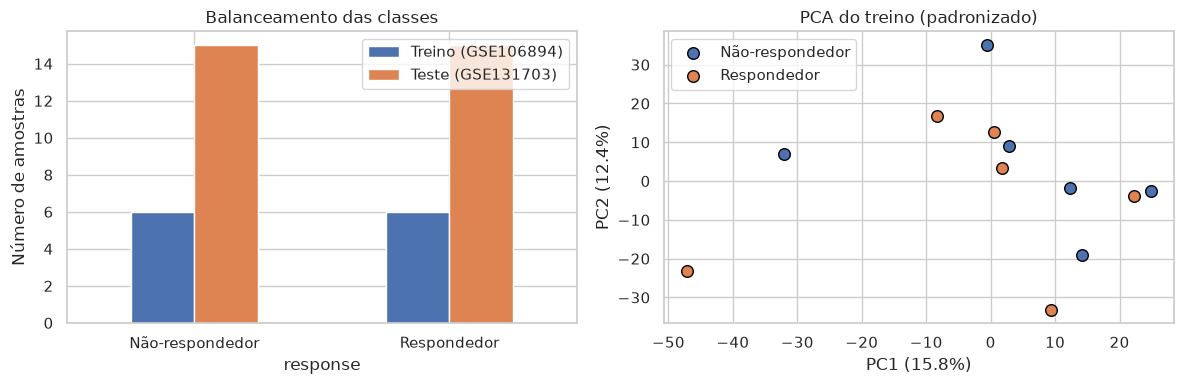

Variância explicada pelas duas primeiras PCs: 28.2%


In [5]:
# Painel com dois gráficos: balanceamento das classes e PCA do treino.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Conta quantas amostras existem em cada classe, no treino e no teste.
balance = pd.DataFrame(
    {
        "Treino (GSE106894)": y_train.value_counts().sort_index(),
        "Teste (GSE131703)": y_test.value_counts().sort_index(),
    }
).rename(index={0: "Não-respondedor", 1: "Respondedor"})
balance.plot(kind="bar", ax=axes[0], color=["#4c72b0", "#dd8452"])
axes[0].set_title("Balanceamento das classes")
axes[0].set_ylabel("Número de amostras")
axes[0].tick_params(axis="x", rotation=0)

# PCA: projeta as amostras do treino em 2D apenas para visualização.
X_scaled_train = StandardScaler().fit_transform(X_train)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_coords = pca.fit_transform(X_scaled_train)
# Plota cada classe com uma cor diferente.
for label, color, name in [(0, "#4c72b0", "Não-respondedor"), (1, "#dd8452", "Respondedor")]:
    mask = (y_train == label).to_numpy()
    axes[1].scatter(
        pca_coords[mask, 0], pca_coords[mask, 1],
        label=name, color=color, s=70, edgecolor="black",
    )
axes[1].set_title("PCA do treino (padronizado)")
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Variância explicada pelas duas primeiras PCs: {pca.explained_variance_ratio_[:2].sum():.1%}")

## Etapa 4 — Modelo: LASSO para seleção + SVM para classificação

O pipeline é sempre ajustado **dentro do fold de treino**:

1. `StandardScaler` — padroniza cada miRNA usando apenas o treino do fold;
2. `LassoSelector` — ajusta um LASSO no alvo 0/1 e mantém apenas miRNAs com coeficiente não nulo (fallback para os top-50 se todos forem zerados);
3. `SVC` — classifica com SVM. Usamos `class_weight="balanced"` e `probability=True`.

O LASSO não vê o fold de teste, e o SVM não vê o GSE131703 até a etapa final. O hiperparâmetro `alpha=0.05` e `C=1.0` são fixados a priori; não há tuning usando o teste.

**Por que LOOCV além da CV repetida?** Com 12 amostras, cada fold de teste da CV 5-fold tem 2–3 amostras, o que torna a AUC por fold extremamente ruidosa. O LOOCV produz uma probabilidade fora da amostra por paciente e permite calcular uma AUC agrupada, mais estável para descrever a linha de base.

In [6]:
# Seletor de features baseado no LASSO, usado dentro do pipeline.
class LassoSelector(BaseEstimator, TransformerMixin):
    '''Seleciona features com coeficiente LASSO não nulo.

    Se o LASSO zerar todas as features, mantém as top-k por magnitude,
    evitando que o SVM receba uma matriz sem colunas.
    '''

    def __init__(self, alpha: float = 0.05, max_features: int = 50):
        self.alpha = alpha
        self.max_features = max_features

    def fit(self, X, y):
        X_array = np.asarray(X, dtype=float)
        y_array = np.asarray(y, dtype=float)

        # Ajusta o LASSO apenas no treino do fold atual.
        lasso = Lasso(alpha=self.alpha, max_iter=100000)
        lasso.fit(X_array, y_array)

        # Coeficientes não nulos indicam os miRNAs selecionados.
        importance = np.abs(lasso.coef_)
        mask = importance > 1e-8
        # Fallback: se o LASSO zerar tudo, mantém as top-k features.
        if not mask.any():
            mask = np.zeros_like(importance, dtype=bool)
            k = min(self.max_features, importance.size)
            mask[np.argsort(importance)[-k:]] = True

        # Guarda a máscara e os índices para transformar o conjunto de teste.
        self.support_ = mask
        self.selected_ = np.flatnonzero(mask)
        self.coef_ = lasso.coef_
        self.intercept_ = lasso.intercept_
        return self

    def transform(self, X):
        # Aplica a mesma máscara aprendida no treino.
        return np.asarray(X, dtype=float)[:, self.selected_]

    def get_support(self):
        return self.support_


# Baseline: padronização + SVM, sem seleção de features.
def make_svm(kernel: str = "linear", C: float = 1.0) -> Pipeline:
    return Pipeline(
        [
            ("scaler", StandardScaler()),
            (
                "svm",
                SVC(
                    kernel=kernel,
                    C=C,
                    gamma="scale",
                    probability=True,
                    class_weight="balanced",
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )


# Modelo principal: padronização -> LASSO -> SVM.
def make_lasso_svm(
    kernel: str = "linear",
    C: float = 1.0,
    alpha: float = 0.05,
) -> Pipeline:
    return Pipeline(
        [
            ("scaler", StandardScaler()),
            ("lasso", LassoSelector(alpha=alpha, max_features=50)),
            (
                "svm",
                SVC(
                    kernel=kernel,
                    C=C,
                    gamma="scale",
                    probability=True,
                    class_weight="balanced",
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )


# Calcula as métricas de classificação usadas no notebook.
def _metrics(y_true, y_pred, y_prob) -> dict:
    '''Calcula acurácia, F1 e AUC para classificação binária.'''
    y_true = np.asarray(y_true)
    auc = (
        roc_auc_score(y_true, y_prob)
        if len(np.unique(y_true)) == 2
        else np.nan
    )
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "auc": auc,
    }


# Estima o intervalo de confiança de 95% da AUC por bootstrap.
def bootstrap_auc_ci(
    y_true,
    y_prob,
    n_boot: int = 2000,
    seed: int = RANDOM_STATE,
) -> tuple[float, float]:
    '''Intervalo de confiança bootstrap de 95% para a AUC.'''
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    aucs = []

    for _ in range(n_boot):
        indices = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[indices])) < 2:
            continue
        aucs.append(roc_auc_score(y_true[indices], y_prob[indices]))

    if not aucs:
        return np.nan, np.nan
    return tuple(np.percentile(aucs, [2.5, 97.5]))


# Modelos comparados na validação interna.
MODELS = {
    "SVM linear (baseline)": make_svm("linear"),
    "SVM RBF (baseline)": make_svm("rbf"),
    "LASSO + SVM linear": make_lasso_svm("linear"),
    "LASSO + SVM RBF": make_lasso_svm("rbf"),
}

print("Modelos definidos:", list(MODELS))

Modelos definidos: ['SVM linear (baseline)', 'SVM RBF (baseline)', 'LASSO + SVM linear', 'LASSO + SVM RBF']


### Etapa 4.1 — Validação cruzada repetida

A CV é estratificada, com 5 folds e 20 repetições (100 ajustes por modelo). Cada fold tem seu próprio scaler e seu próprio LASSO. O resumo abaixo mostra média e desvio-padrão entre folds; a variabilidade alta é esperada com n = 12.

In [7]:
# Validação cruzada estratificada repetida: 5 folds x 20 repetições.
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=20,
    random_state=RANDOM_STATE,
)

# Avalia cada modelo em cada fold, sempre ajustando apenas no treino.
cv_rows = []
for model_name, model in MODELS.items():
    for fold, (train_idx, test_idx) in enumerate(cv.split(X_train, y_train), start=1):
        fitted = model.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        y_pred = fitted.predict(X_train.iloc[test_idx])
        y_prob = fitted.predict_proba(X_train.iloc[test_idx])[:, 1]

        cv_rows.append(
            {
                "model": model_name,
                "fold": fold,
                "n_train": len(train_idx),
                "n_test": len(test_idx),
                **_metrics(y_train.iloc[test_idx], y_pred, y_prob),
            }
        )

# Guarda os resultados por fold e o resumo agregado.
cv_results = pd.DataFrame(cv_rows)
cv_results.to_csv(RESULTS_DIR / "vcp_cv_repetida.csv", index=False)

cv_summary = (
    cv_results.groupby("model")[["accuracy", "f1", "auc"]]
    .agg(["mean", "std"])
    .round(3)
)
display(cv_summary)

accuracy            f1           auc       
                          mean    std   mean    std   mean    std
model                                                            
LASSO + SVM RBF          0.435  0.339  0.475  0.374  0.405  0.464
LASSO + SVM linear       0.423  0.343  0.490  0.367  0.460  0.480
SVM RBF (baseline)       0.308  0.218  0.127  0.243  0.875  0.296
SVM linear (baseline)    0.332  0.269  0.315  0.344  0.700  0.426

### Etapa 4.2 — LOOCV com AUC agrupada

Cada paciente do treino é deixado de fora uma vez. As probabilidades fora da amostra são reunidas e a AUC é calculada uma única vez sobre os 12 pacientes. Isso evita a média de AUCs instáveis calculadas em folds de 2–3 amostras.

In [8]:
# LOOCV: cada amostra do treino é deixada de fora uma vez.
loo = LeaveOneOut()
loocv_rows = []
loocv_probabilities = {}

# Gera uma probabilidade fora da amostra para cada paciente.
for model_name, model in MODELS.items():
    y_prob = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=loo,
        method="predict_proba",
    )[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    # Calcula a AUC agrupada e o intervalo de confiança bootstrap.
    auc_low, auc_high = bootstrap_auc_ci(y_train.values, y_prob)
    loocv_probabilities[model_name] = y_prob
    loocv_rows.append(
        {
            "model": model_name,
            **_metrics(y_train.values, y_pred, y_prob),
            "auc_ci_low": auc_low,
            "auc_ci_high": auc_high,
        }
    )

loocv_results = pd.DataFrame(loocv_rows)
loocv_results.to_csv(RESULTS_DIR / "vcp_loocv.csv", index=False)
display(loocv_results.round(3))

,model,accuracy,f1,auc,auc_ci_low,auc_ci_high
0,SVM linear (baseline),0.583,0.444,0.611,0.250,0.943
1,SVM RBF (baseline),0.000,0.000,0.000,0.000,0.000
2,LASSO + SVM linear,0.417,0.533,0.417,0.056,0.772
3,LASSO + SVM RBF,0.500,0.571,0.389,0.056,0.772


### Etapa 4.3 — Estabilidade da seleção LASSO

A estabilidade é medida pela frequência com que cada miRNA é selecionado nos 100 folds de treino. Um critério comum de estabilidade é frequência ≥ 0,70. O resultado abaixo mostra se a assinatura é reproduzível ou dependente do fold.

Folds avaliados: 100
miRNAs selecionados ao menos uma vez: 164
Frequência máxima de seleção: 51.0%
miRNAs com frequência >= 70%: 0
miRNAs com frequência >= 50%: 1


,feature,n_folds,frequency
28,hsa-miR-376a-5p,51,0.51
32,hsa-miR-7850-5p,34,0.34
17,hsa-miR-3684,32,0.32
6,hsa-miR-3117-3p,30,0.30
50,hsa-miR-3912-5p,24,0.24
31,hsa-miR-6779-5p,22,0.22
0,hsa-miR-3126-3p,19,0.19
24,hsa-miR-585-5p,19,0.19
14,hsa-miR-3167,18,0.18
1,hsa-miR-3923,17,0.17


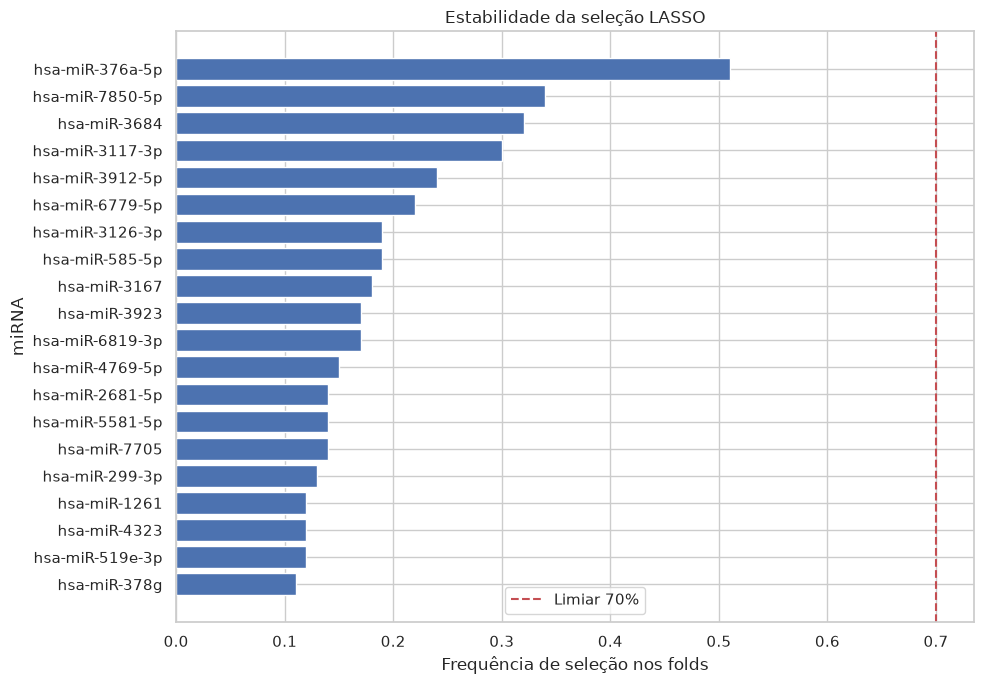

In [9]:
# Conta em quantos folds cada miRNA foi selecionado pelo LASSO.
stability_counts = Counter()
n_folds = 0

# Reajusta o LASSO em cada fold de treino da validação cruzada.
for train_idx, _ in cv.split(X_train, y_train):
    fitted = make_lasso_svm("linear").fit(
        X_train.iloc[train_idx], y_train.iloc[train_idx]
    )
    support = fitted.named_steps["lasso"].get_support()
    for feature in X_train.columns[support]:
        stability_counts[feature] += 1
    n_folds += 1

# Frequência = folds em que o miRNA foi selecionado / total de folds.
stability = pd.DataFrame(
    [
        {"feature": feature, "n_folds": count, "frequency": count / n_folds}
        for feature, count in stability_counts.items()
    ]
).sort_values(["frequency", "feature"], ascending=[False, True])

stability.to_csv(RESULTS_DIR / "vcp_estabilidade_lasso.csv", index=False)

# Indicadores de estabilidade: frequência máxima e limiares de 50% e 70%.
max_frequency = stability["frequency"].max() if not stability.empty else 0.0
n_stable_70 = int((stability["frequency"] >= 0.70).sum())
n_stable_50 = int((stability["frequency"] >= 0.50).sum())

print(f"Folds avaliados: {n_folds}")
print(f"miRNAs selecionados ao menos uma vez: {len(stability)}")
print(f"Frequência máxima de seleção: {max_frequency:.1%}")
print(f"miRNAs com frequência >= 70%: {n_stable_70}")
print(f"miRNAs com frequência >= 50%: {n_stable_50}")

display(stability.head(20).round(3))

# Gráfico dos 20 miRNAs mais frequentes nos folds.
top_stability = stability.head(20).iloc[::-1]
plt.figure(figsize=(10, 7))
plt.barh(top_stability["feature"], top_stability["frequency"], color="#4c72b0")
plt.axvline(0.70, color="#c44e52", linestyle="--", label="Limiar 70%")
plt.xlabel("Frequência de seleção nos folds")
plt.ylabel("miRNA")
plt.title("Estabilidade da seleção LASSO")
plt.legend()
plt.tight_layout()
plt.show()

## Etapa 5 — Modelo final e assinatura

O modelo final é treinado em todas as 12 amostras do GSE106894 com a mesma configuração avaliada na CV. A assinatura é o conjunto de miRNAs com coeficiente LASSO não nulo; os pesos do SVM linear indicam a direção da contribuição de cada miRNA no hiperplano.

In [10]:
# Treina o modelo final em todas as amostras do GSE106894.
final_model = make_lasso_svm("linear", C=1.0, alpha=0.05).fit(X_train, y_train)

# Recupera a máscara do LASSO e os coeficientes do SVM linear.
support = final_model.named_steps["lasso"].get_support()
selected_features = X_train.columns[support]
svm_coefficients = final_model.named_steps["svm"].coef_.ravel()
lasso_coefficients = final_model.named_steps["lasso"].coef_[support]

# Monta a tabela da assinatura final.
signature = pd.DataFrame(
    {
        "feature": selected_features,
        "lasso_coefficient": lasso_coefficients,
        "svm_coefficient": svm_coefficients,
    }
)
# Ordena pelos pesos absolutos do SVM.
signature["abs_svm_coefficient"] = signature["svm_coefficient"].abs()
signature = signature.sort_values(
    "abs_svm_coefficient", ascending=False
).reset_index(drop=True)

signature.to_csv(RESULTS_DIR / "vcp_assinatura_mirnas.csv", index=False)
print(f"miRNAs selecionados pelo LASSO final: {len(signature)}")
display(signature.round(4))

miRNAs selecionados pelo LASSO final: 10


,feature,lasso_coefficient,svm_coefficient,abs_svm_coefficient
0,hsa-miR-376a-5p,-0.1972,-0.2558,0.2558
1,hsa-miR-3684,0.0602,0.1706,0.1706
2,hsa-miR-519e-3p,0.0911,0.1672,0.1672
3,hsa-miR-4707-3p,0.0507,0.1611,0.1611
4,hsa-miR-6876-3p,-0.0360,-0.1528,0.1528
5,hsa-miR-3117-3p,-0.0305,-0.1480,0.1480
6,hsa-miR-7850-5p,0.0506,0.1346,0.1346
7,hsa-miR-3923,0.0166,0.1248,0.1248
8,hsa-miR-4506,-0.0174,-0.0870,0.0870
9,hsa-miR-4659b-3p,-0.0105,-0.0708,0.0708


## Etapa 6 — Teste Zero-Shot no GSE131703

O modelo é congelado e aplicado diretamente ao GSE131703. Não há re-treino, re-escalonamento com dados do teste, re-seleção de features ou ajuste de limiar. O limiar permanece 0,5. A AUC é acompanhada de um intervalo bootstrap de 95%.

Métricas Zero-Shot no GSE131703:
  accuracy: 0.500
  f1: 0.000
  auc: 0.436
  AUC IC95% bootstrap: [0.230, 0.662]
  Previstos como respondedores: 0/30
  Acurácia de um classificador trivial que prevê não-respondedor: 0.500

Relatório de classificação:
                 precision    recall  f1-score   support

Não-respondedor      0.500     1.000     0.667        15
    Respondedor      0.000     0.000     0.000        15

       accuracy                          0.500        30
      macro avg      0.250     0.500     0.333        30
   weighted avg      0.250     0.500     0.333        30



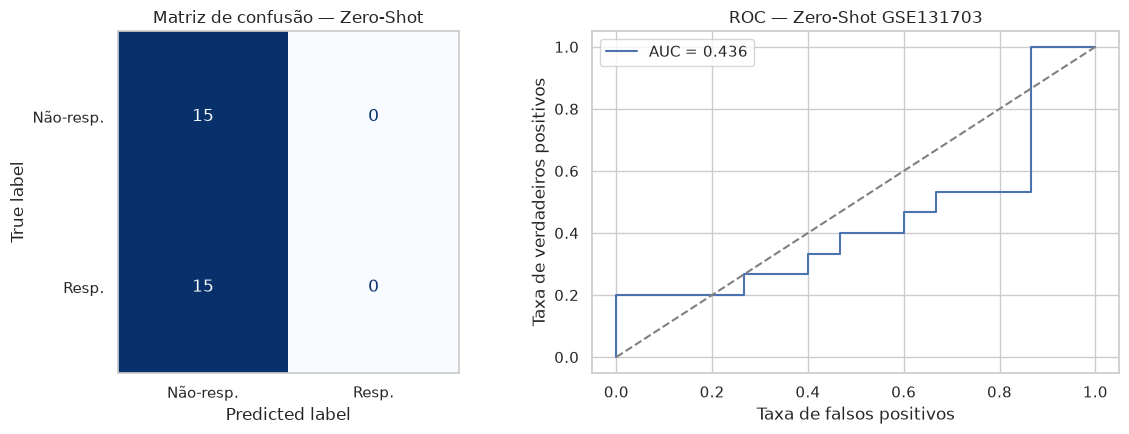

,amostra,y_true,y_pred,probabilidade
0,MG_NR10,0,0,0.016744
1,MG_R10,1,0,0.005326
2,MG_NR6,0,0,0.023615
3,MG_R1,1,0,0.004862
4,MG_NR13,0,0,0.018769
5,MG_NR4,0,0,0.005603
6,MG_R9,1,0,0.001125
7,MG_R2,1,0,0.005143
8,MG_R6,1,0,0.003166
9,MG_NR14,0,0,0.005496


In [11]:
# Aplica o modelo congelado no GSE131703, sem re-treino ou ajuste.
y_prob_test = final_model.predict_proba(X_test)[:, 1]
y_pred_test = final_model.predict(X_test)

# Calcula as métricas externas e o IC bootstrap da AUC.
zero_shot_metrics = _metrics(y_test, y_pred_test, y_prob_test)
auc_low, auc_high = bootstrap_auc_ci(y_test.values, y_prob_test)

print("Métricas Zero-Shot no GSE131703:")
for metric, value in zero_shot_metrics.items():
    print(f"  {metric}: {value:.3f}")
print(f"  AUC IC95% bootstrap: [{auc_low:.3f}, {auc_high:.3f}]")
print(f"  Previstos como respondedores: {int(y_pred_test.sum())}/{len(y_pred_test)}")
print(
    "  Acurácia de um classificador trivial que prevê não-respondedor: "
    f"{accuracy_score(y_test, np.zeros_like(y_test)):.3f}"
)

# Relatório de precisão, recall e F1 por classe.
print("\nRelatório de classificação:")
print(
    classification_report(
        y_test,
        y_pred_test,
        target_names=["Não-respondedor", "Respondedor"],
        digits=3,
        zero_division=0,
    )
)

# Matriz de confusão e curva ROC do teste externo.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, y_pred_test)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Não-resp.", "Resp."],
).plot(cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Matriz de confusão — Zero-Shot")
axes[0].grid(False)

fpr, tpr, _ = roc_curve(y_test, y_prob_test)
axes[1].plot(fpr, tpr, label=f"AUC = {zero_shot_metrics['auc']:.3f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_xlabel("Taxa de falsos positivos")
axes[1].set_ylabel("Taxa de verdadeiros positivos")
axes[1].set_title("ROC — Zero-Shot GSE131703")
axes[1].legend()

plt.tight_layout()
plt.show()

# Salva as previsões por amostra para auditoria.
previsoes = pd.DataFrame(
    {
        "amostra": X_test.index,
        "y_true": y_test.values,
        "y_pred": y_pred_test,
        "probabilidade": y_prob_test,
    }
)
previsoes.to_csv(RESULTS_DIR / "vcp_previsoes_zero_shot.csv", index=False)
display(previsoes.head(10))

## Etapa 7 — Resumo comparativo

A tabela reúne a melhor estimativa interna (LOOCV) e o desempenho externo (Zero-Shot). A comparação entre as duas linhas mostra se o sinal aprendido no treino sobrevive à mudança de doença e de plataforma.

In [12]:
# Compara a estimativa interna (LOOCV) com o teste externo (Zero-Shot).
resumo = pd.DataFrame(
    [
        {
            "etapa": "LOOCV — LASSO + SVM linear",
            "modelo": "LASSO + SVM linear",
            "accuracy": loocv_results.loc[
                loocv_results["model"] == "LASSO + SVM linear", "accuracy"
            ].iloc[0],
            "f1": loocv_results.loc[
                loocv_results["model"] == "LASSO + SVM linear", "f1"
            ].iloc[0],
            "auc": loocv_results.loc[
                loocv_results["model"] == "LASSO + SVM linear", "auc"
            ].iloc[0],
        },
        {
            "etapa": "Zero-Shot — LASSO + SVM linear",
            "modelo": "LASSO + SVM linear",
            "accuracy": zero_shot_metrics["accuracy"],
            "f1": zero_shot_metrics["f1"],
            "auc": zero_shot_metrics["auc"],
        },
    ]
)
# Salva o resumo final em CSV.
resumo.to_csv(RESULTS_DIR / "vcp_resumo_metricas.csv", index=False)
display(resumo.round(3))

,etapa,modelo,accuracy,f1,auc
0,LOOCV — LASSO + SVM linear,LASSO + SVM linear,0.417,0.533,0.417
1,Zero-Shot — LASSO + SVM linear,LASSO + SVM linear,0.500,0.000,0.436


## Leitura dos resultados

- **LOOCV com AUC agrupada:** SVM linear baseline **AUC 0,611** (IC bootstrap 95% 0,250–0,943); LASSO + SVM linear **AUC 0,417** (IC 0,056–0,772); SVM RBF 0,000; LASSO + SVM RBF 0,389. O baseline linear é a referência interna mais informativa; o LASSO não melhorou a classificação.
- **CV repetida (100 folds):** baseline linear AUC **0,700 ± 0,426**; LASSO + SVM linear AUC **0,460 ± 0,480**. O desvio-padrão muito alto confirma que a estimativa é instável com n = 12.
- **Estabilidade do LASSO:** 164 miRNAs foram selecionados ao menos uma vez; a frequência máxima foi **51,0%** (`hsa-miR-376a-5p`) e **nenhum miRNA atingiu 70%**. A assinatura é dependente do fold.
- **Zero-Shot no GSE131703:** AUC **0,436** (IC 0,230–0,662), acurácia **0,500**, F1 **0,000**. O modelo previu **todos os 30 pacientes como não-respondedores**. A assinatura aprendida na artrite reumatoide não transfere para a miastenia gravis.

## Conclusões e limitações

1. **Pipeline fechado e sem vazamento:** scaler, LASSO e SVM são ajustados apenas no treino de cada fold. O GSE131703 só é tocado na Etapa 6.
2. **Linha de base:** o SVM linear é a referência; o LOOCV com AUC agrupada (0,611) é a estimativa interna menos ruidosa. A CV repetida é reportada com desvio-padrão justamente para explicitar a instabilidade.
3. **LASSO:** a seleção é esparsa, mas instável (frequência máxima 51,0%; nenhum miRNA ≥ 70%). Com n = 12, a assinatura não deve ser tratada como biomarcador.
4. **Zero-Shot:** AUC 0,436 no GSE131703, com todos previstos como não-respondedores. Não há evidência de transferência entre artrite reumatoide (microarray, PBMC) e miastenia gravis (miRNA-seq, sangue total).
5. **Limitações:** n = 12 no treino; p = 2.578 miRNAs; diferenças de plataforma e tecido; ausência de harmonização entre domínios; LASSO e SVM com hiperparâmetros fixados a priori. O resultado é exploratório e não prova causalidade biológica.
6. **Escopo:** as bases sem rótulo R/NR (GSE140106, GSE215450, GSE230064) não são usadas aqui. Elas pertencem ao TCC, onde podem ser exploradas com pré-treinamento não supervisionado ou adaptação de domínio.

## Interpretação e conclusão prática

### O que a hipótese previa

A hipótese era que existem perfis de miRNA associados à refratariedade e que esse sinal é consistente entre doenças autoimunes. Em termos operacionais, uma assinatura aprendida na artrite reumatoide (`GSE106894`) deveria prever refratariedade na miastenia gravis (`GSE131703`) em cenário Zero-Shot, sem re-treino.

### O que os resultados mostram

- O baseline SVM linear teve AUC LOOCV de **0,611**, mas o LASSO + SVM caiu para **0,417**.
- No Zero-Shot, a AUC foi **0,436**, a acurácia **0,500** e o F1 **0,000**; todos os 30 pacientes foram previstos como não-respondedores.
- A seleção LASSO foi instável: o miRNA mais frequente apareceu em **51%** dos folds e nenhum atingiu o limiar de 70%.

Portanto, **não há evidência, neste desenho, de que a assinatura de artrite reumatoide generalize para miastenia gravis**.

### O que isso não significa

O resultado **não prova** que não exista sinal biológico. Ele mostra que este pipeline específico, com n = 12 no treino, plataformas diferentes (microarray vs. miRNA-seq) e tecidos diferentes (PBMC vs. sangue total), não conseguiu demonstrar transferência. A instabilidade do LASSO reforça que a assinatura é exploratória e dependente do fold.

### Conclusão prática do VCP

O trabalho entrega um pipeline fechado, reprodutível e sem vazamento de dados, com validação interna (CV repetida e LOOCV), análise de estabilidade e teste externo honesto. O resultado negativo é parte da conclusão: a assinatura não é um biomarcador validado. A hipótese permanece em aberto para o TCC, onde podem ser testadas adaptação de domínio e pré-treinamento não supervisionado com as bases sem rótulo.